In [4]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import cv2
print(cv2.__version__)

5.0.0


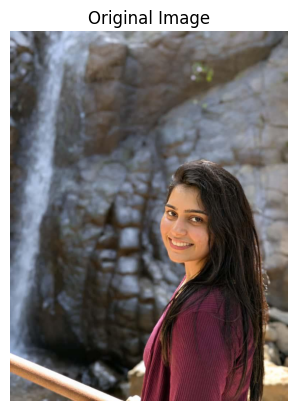

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("input/photo1.jpeg")

if img is None:
    raise FileNotFoundError("Image not found!")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

Task 1: Image Restoration and Segmentation

Aim: To perform image restoration and segmentation using Python and OpenCV.

Input: An original photograph containing a person, waterfall and rocky background.

Objective: To apply noise, filtering, thresholding, morphological operations, edge detection and watershed segmentation, and compare the results.
    

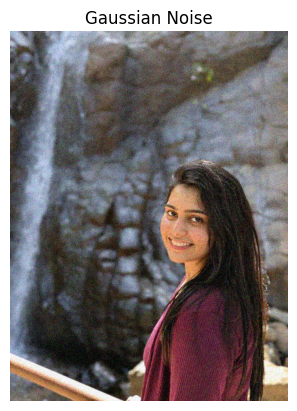

True

In [11]:
# Add Gaussian Noise
noise = np.random.normal(0, 25, img.shape)

gaussian_noisy = img.astype(np.float32) + noise
gaussian_noisy = np.clip(gaussian_noisy, 0, 255).astype(np.uint8)

plt.imshow(cv2.cvtColor(gaussian_noisy, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Noise")
plt.axis("off")
plt.show()

cv2.imwrite("output/gaussian_noise.jpg", gaussian_noisy)

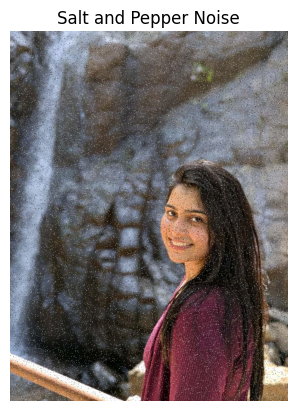

True

In [12]:
# Add Salt-and-Pepper Noise
sp_noisy = img.copy()

prob = 0.05
random_values = np.random.rand(img.shape[0], img.shape[1])

sp_noisy[random_values < prob / 2] = 0
sp_noisy[random_values > 1 - prob / 2] = 255

plt.imshow(cv2.cvtColor(sp_noisy, cv2.COLOR_BGR2RGB))
plt.title("Salt and Pepper Noise")
plt.axis("off")
plt.show()

cv2.imwrite("output/salt_pepper_noise.jpg", sp_noisy)

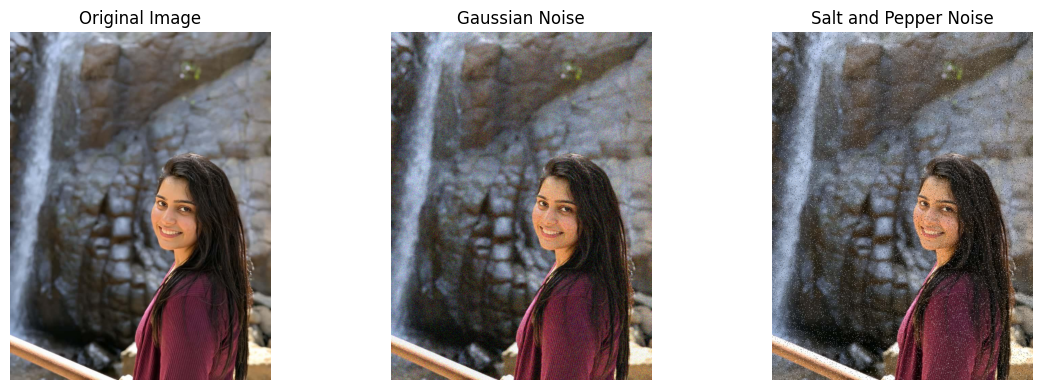

In [13]:
plt.figure(figsize=(12, 4))

images = [img, gaussian_noisy, sp_noisy]
titles = ["Original Image", "Gaussian Noise", "Salt and Pepper Noise"]

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

Observation:

Gaussian noise introduces random intensity variations throughout the image, while salt-and-pepper noise produces scattered black and white pixels. The original photograph remains clear, whereas both noisy images show reduced visual quality.

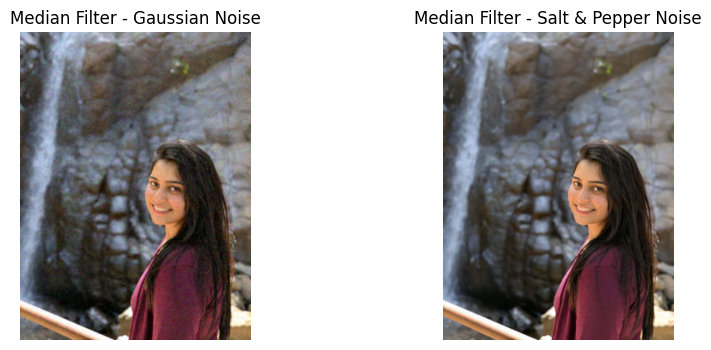

True

In [14]:
# Median Filtering
median_gaussian = cv2.medianBlur(gaussian_noisy, 5)
median_sp = cv2.medianBlur(sp_noisy, 5)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(median_gaussian, cv2.COLOR_BGR2RGB))
plt.title("Median Filter - Gaussian Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(median_sp, cv2.COLOR_BGR2RGB))
plt.title("Median Filter - Salt & Pepper Noise")
plt.axis("off")

plt.show()

cv2.imwrite("output/median_gaussian.jpg", median_gaussian)
cv2.imwrite("output/median_sp.jpg", median_sp)

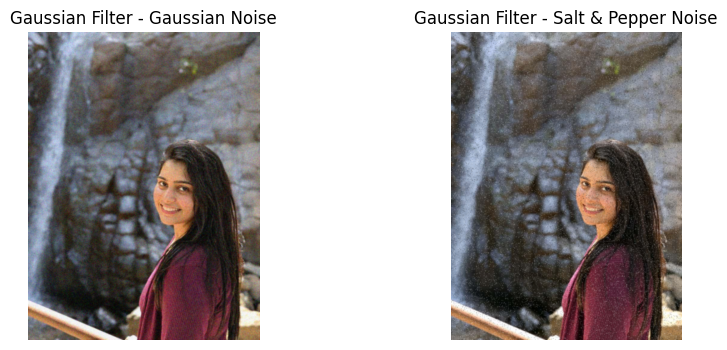

True

In [15]:
# Gaussian Filtering
filtered_gaussian = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)
filtered_sp = cv2.GaussianBlur(sp_noisy, (5, 5), 0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(filtered_gaussian, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Filter - Gaussian Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(filtered_sp, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Filter - Salt & Pepper Noise")
plt.axis("off")

plt.show()

cv2.imwrite("output/filtered_gaussian.jpg", filtered_gaussian)
cv2.imwrite("output/filtered_sp.jpg", filtered_sp)

In [17]:
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

images = {
    "Gaussian Noise": gaussian_noisy,
    "Salt & Pepper Noise": sp_noisy,
    "Median - Gaussian": median_gaussian,
    "Median - S&P": median_sp,
    "Gaussian Filter - Gaussian": filtered_gaussian,
    "Gaussian Filter - S&P": filtered_sp
}

print(f"{'Image':<28} {'PSNR':<12} {'SSIM':<12}")
print("-" * 52)

for name, image in images.items():
    psnr = peak_signal_noise_ratio(img, image, data_range=255)
    ssim = structural_similarity(img, image, channel_axis=2, data_range=255)

    print(f"{name:<28} {psnr:<12.2f} {ssim:<12.4f}")

Image                        PSNR         SSIM        
----------------------------------------------------
Gaussian Noise               20.43        0.2129      
Salt & Pepper Noise          18.16        0.2750      
Median - Gaussian            30.52        0.7347      
Median - S&P                 36.28        0.9418      
Gaussian Filter - Gaussian   30.63        0.7259      
Gaussian Filter - S&P        28.43        0.6593      


Observation:

Median filtering is generally more suitable for removing salt-and-pepper noise, while Gaussian filtering is useful for reducing Gaussian noise. Both filtering techniques improve image quality, although some image details may be lost due to smoothing. PSNR and SSIM are used to compare the restored images with the original photograph.

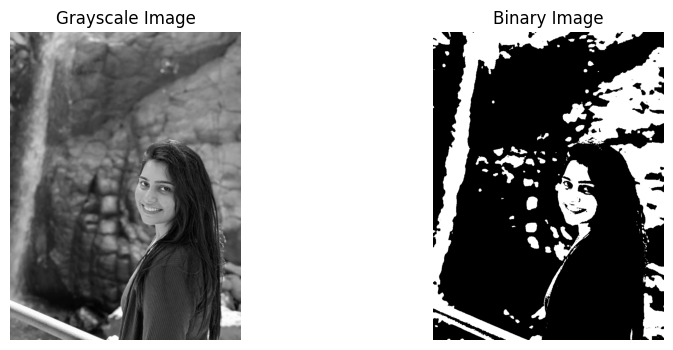

True

In [18]:
# Grayscale and Binary Thresholding

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()

cv2.imwrite("output/grayscale.jpg", gray)
cv2.imwrite("output/binary.jpg", binary)

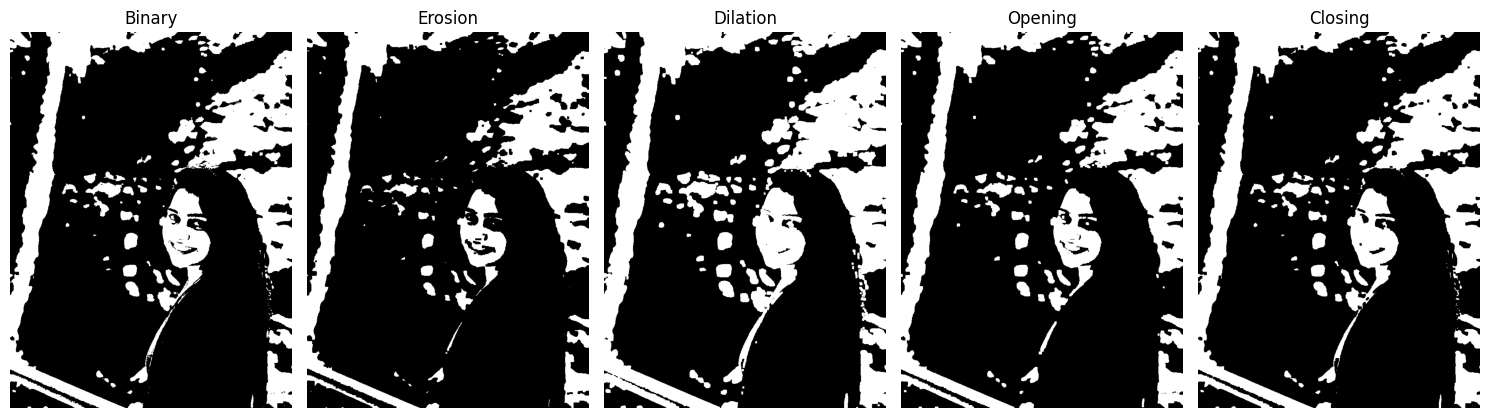

True

In [19]:
# Morphological Operations

kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)

opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

images = [binary, erosion, dilation, opening, closing]

titles = ["Binary", "Erosion", "Dilation", "Opening", "Closing"]

plt.figure(figsize=(15, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("output/erosion.jpg", erosion)
cv2.imwrite("output/dilation.jpg", dilation)
cv2.imwrite("output/opening.jpg", opening)
cv2.imwrite("output/closing.jpg", closing)

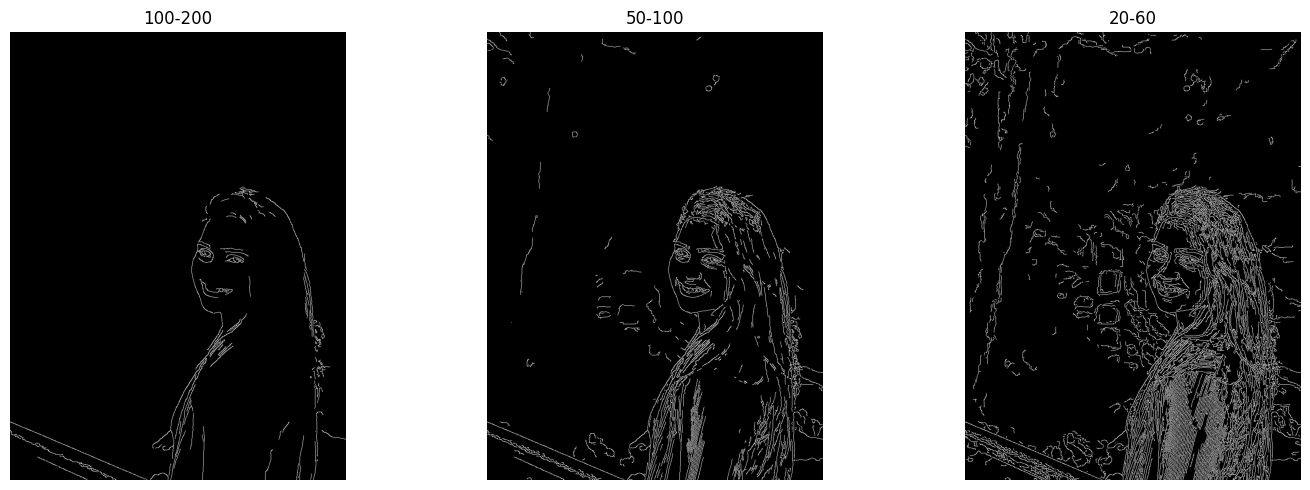

Canny Edge Detection saved successfully!


In [25]:
# Canny Edge Detection

blur = cv2.GaussianBlur(gray, (3, 3), 0)

edges1 = cv2.Canny(blur, 100, 200)
edges2 = cv2.Canny(blur, 50, 100)
edges3 = cv2.Canny(blur, 20, 60)

plt.figure(figsize=(15, 5))

images = [edges1, edges2, edges3]
titles = ["100-200", "50-100", "20-60"]

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

edges = edges3

cv2.imwrite("outputs/canny_edges.jpg", edges)

print("Canny Edge Detection saved successfully!")

Observation: Canny Edge Detection identified the boundaries of the person clearly. The rocks and waterfall produced weaker edges because of their blurred background textures. Reducing the threshold values helped detect additional edges, but also increased unwanted noise.


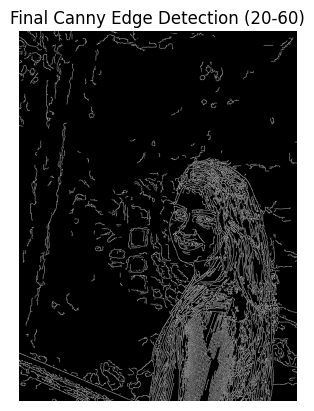

In [26]:
edges = cv2.Canny(blur, 20, 60)

cv2.imwrite("output/canny_edges.jpg", edges)

plt.imshow(edges, cmap="gray")
plt.title("Final Canny Edge Detection (20-60)")
plt.axis("off")
plt.show()

Observation: Three Canny threshold combinations were tested: 100–200, 50–100, and 20–60. The 20–60 threshold produced the most useful results for the selected photograph, detecting more details around the person, rocks, and waterfall. However, lower thresholds may also detect additional noise.

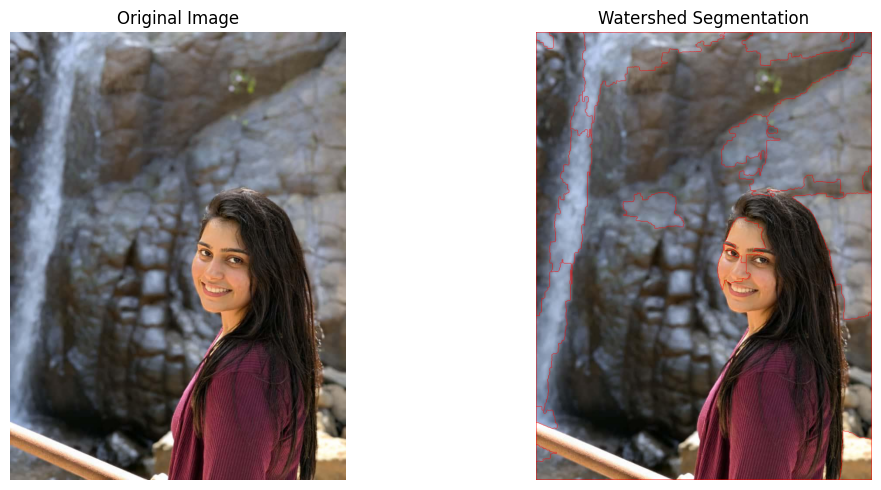

True

In [27]:
# Watershed Segmentation

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Binary Thresholding
_, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# Identify background and foreground
background = cv2.dilate(opening, kernel, iterations=3)

dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

_, foreground = cv2.threshold(dist, 0.3 * dist.max(), 255, 0)
foreground = foreground.astype(np.uint8)

unknown = cv2.subtract(background, foreground)

# Create markers
_, markers = cv2.connectedComponents(foreground)
markers = markers + 1
markers[unknown == 255] = 0

# Apply Watershed
result = img.copy()
markers = cv2.watershed(result, markers)

result[markers == -1] = [0, 0, 255]

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("output/watershed.jpg", result)

Watershed Segmentation – Observation
The Watershed algorithm was applied to the original photograph containing a person, waterfall and rocky background. The algorithm identified several regions, and their boundaries were highlighted in red.

The boundaries around the person and some background structures were successfully detected. However, the complex background caused irregular segmentation.

Conclusion: Watershed segmentation can identify different regions of an image, but its accuracy depends on the foreground-background separation and image complexity.
